# Pretrain model yolov8m-seg

## SetUp

### Import Library

In [ ]:
from glob import glob
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt 
from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

In [3]:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "0.0"
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

### Set SEED

In [4]:
SEED = 2345

os.environ['PYTHONHASHSEED'] = str(SEED)

## tools

### Show train sample images

In [5]:
def show_train_samples_yolo(folder_name, num_samples=3):
    img_files = sorted(glob(f"../data/{folder_name}/train/images/*.jpg"))
    
    if not img_files:
        print("not found images")
        return

    selected_files = img_files[:num_samples]
    
    fig, axes = plt.subplots(nrows=len(selected_files), ncols=3, figsize=(15, 5 * len(selected_files)))
    if len(selected_files) == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx, img_path in enumerate(selected_files):
        img_bgr = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w, _ = img_rgb.shape

        label_path = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
        
        mask = np.zeros((h, w), dtype=np.uint8)

        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                lines = f.readlines()
                for line in lines:
                    parts = list(map(float, line.strip().split()))
                    
                    if len(parts) > 5:
                        coords = np.array(parts[1:], dtype=np.float32).reshape(-1, 2)
                        coords[:, 0] *= w 
                        coords[:, 1] *= h 
                        pts = coords.astype(np.int32)
                        cv2.fillPoly(mask, [pts], color=255)

        overlay = img_rgb.copy()
        color_mask = np.zeros_like(img_rgb)
        color_mask[mask > 0] = [0, 255, 0]
        overlay = cv2.addWeighted(overlay, 1.0, color_mask, 0.5, 0)

        axes[idx, 0].imshow(img_rgb)
        axes[idx, 0].set_title(f"Image", fontsize=10)
        axes[idx, 0].axis("off")

        axes[idx, 1].imshow(mask, cmap="gray")
        axes[idx, 1].set_title("Mask", fontsize=10)
        axes[idx, 1].axis("off")

        axes[idx, 2].imshow(overlay)
        axes[idx, 2].set_title("Image + Mask Overlay", fontsize=10)
        axes[idx, 2].axis("off")

    plt.tight_layout()
    plt.show()

### Plot Evaluation & Validation

In [6]:
def evaluataion(model_name, iter=1):
  runs_dir = f"../runs/models/{model_name}/train_ep{iter}"

  fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(15, 2 * 3.5))
    
  axes[0].imshow(cv2.imread(f"{runs_dir}/results.png")[:, :, ::-1])
  axes[0].axis('off')

  axes[1].imshow(cv2.imread(f"{runs_dir}/confusion_matrix.png")[:, :, ::-1])
  axes[1].axis('off')

  plt.tight_layout()
  plt.show()

In [7]:
def validation(model_name, iter=1):
  runs_dir = f"../runs/models/{model_name}/train_ep{iter}"

  fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 2 * 3.5))
  axes.flatten()
    
  axes[0].imshow(cv2.imread(f"{runs_dir}/val_batch0_labels.jpg")[:, :, ::-1])
  axes[0].set_title('labels valid')
  axes[0].axis('off')

  axes[1].imshow(cv2.imread(f"{runs_dir}/val_batch0_pred.jpg")[:, :, ::-1])
  axes[1].set_title('predict valid')
  axes[1].axis('off')

  plt.tight_layout()
  plt.show()

### Prepocess test image

In [8]:
def preprocess_test(filepath="../data/test_fish/*.jpg"):
  files = sorted(glob(filepath), key=lambda x: int(x.split("-")[-1].split(".")[0]))

  cleaned_imgs = []

  for file in files:
    file_name = file.split("/")[-1].split(".")[0]

    img = cv2.imread(file)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, mask_text = cv2.threshold(gray, 240, 255, cv2.THRESH_BINARY)

    kernel = np.ones((3, 3), np.uint8)
    mask_text = cv2.dilate(mask_text, kernel, iterations=2) 

    cleaned_img = cv2.inpaint(img, mask_text, inpaintRadius=3, flags=cv2.INPAINT_TELEA)
    cleaned_img_rgb = cv2.cvtColor(cleaned_img, cv2.COLOR_BGR2RGB)
    cleaned_imgs.append({"name": file_name, 
                       "pixel_array": cleaned_img_rgb,
                       "path": file})

  return cleaned_imgs

### Show 10 images

In [9]:
def show_10_images(lst_images):
  total_cleaned = len(lst_images)

  fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(15, 10))
  axes = axes.flatten()

  for i in range(total_cleaned):
    pixel = lst_images[i]["pixel_array"]
    name = lst_images[i]["name"]
    
    axes[i].imshow(pixel)
    axes[i].set_title(name, fontsize=10)
    axes[i].axis('off')

  plt.tight_layout()
  plt.show()

## Train model

In [10]:
model = YOLO("../models/yolov8m-seg.pt")

### fish_counting_seg_v3

Dataset: ../data/fish_dataset_5_images2 <br>
Train: 13 images | Val: 1 image <br>
Data Augmentation:
- Outputs per training example: 3
- Flip: Horizontal, Vertical
- Rotation: Between -15° and +15°
- Grayscale: Apply to 15% of images
- Brightness: Between -25% and +25%
- Blur: Up to 4px
- Noise: Up to 1.96% of pixels

##### Show train sample images

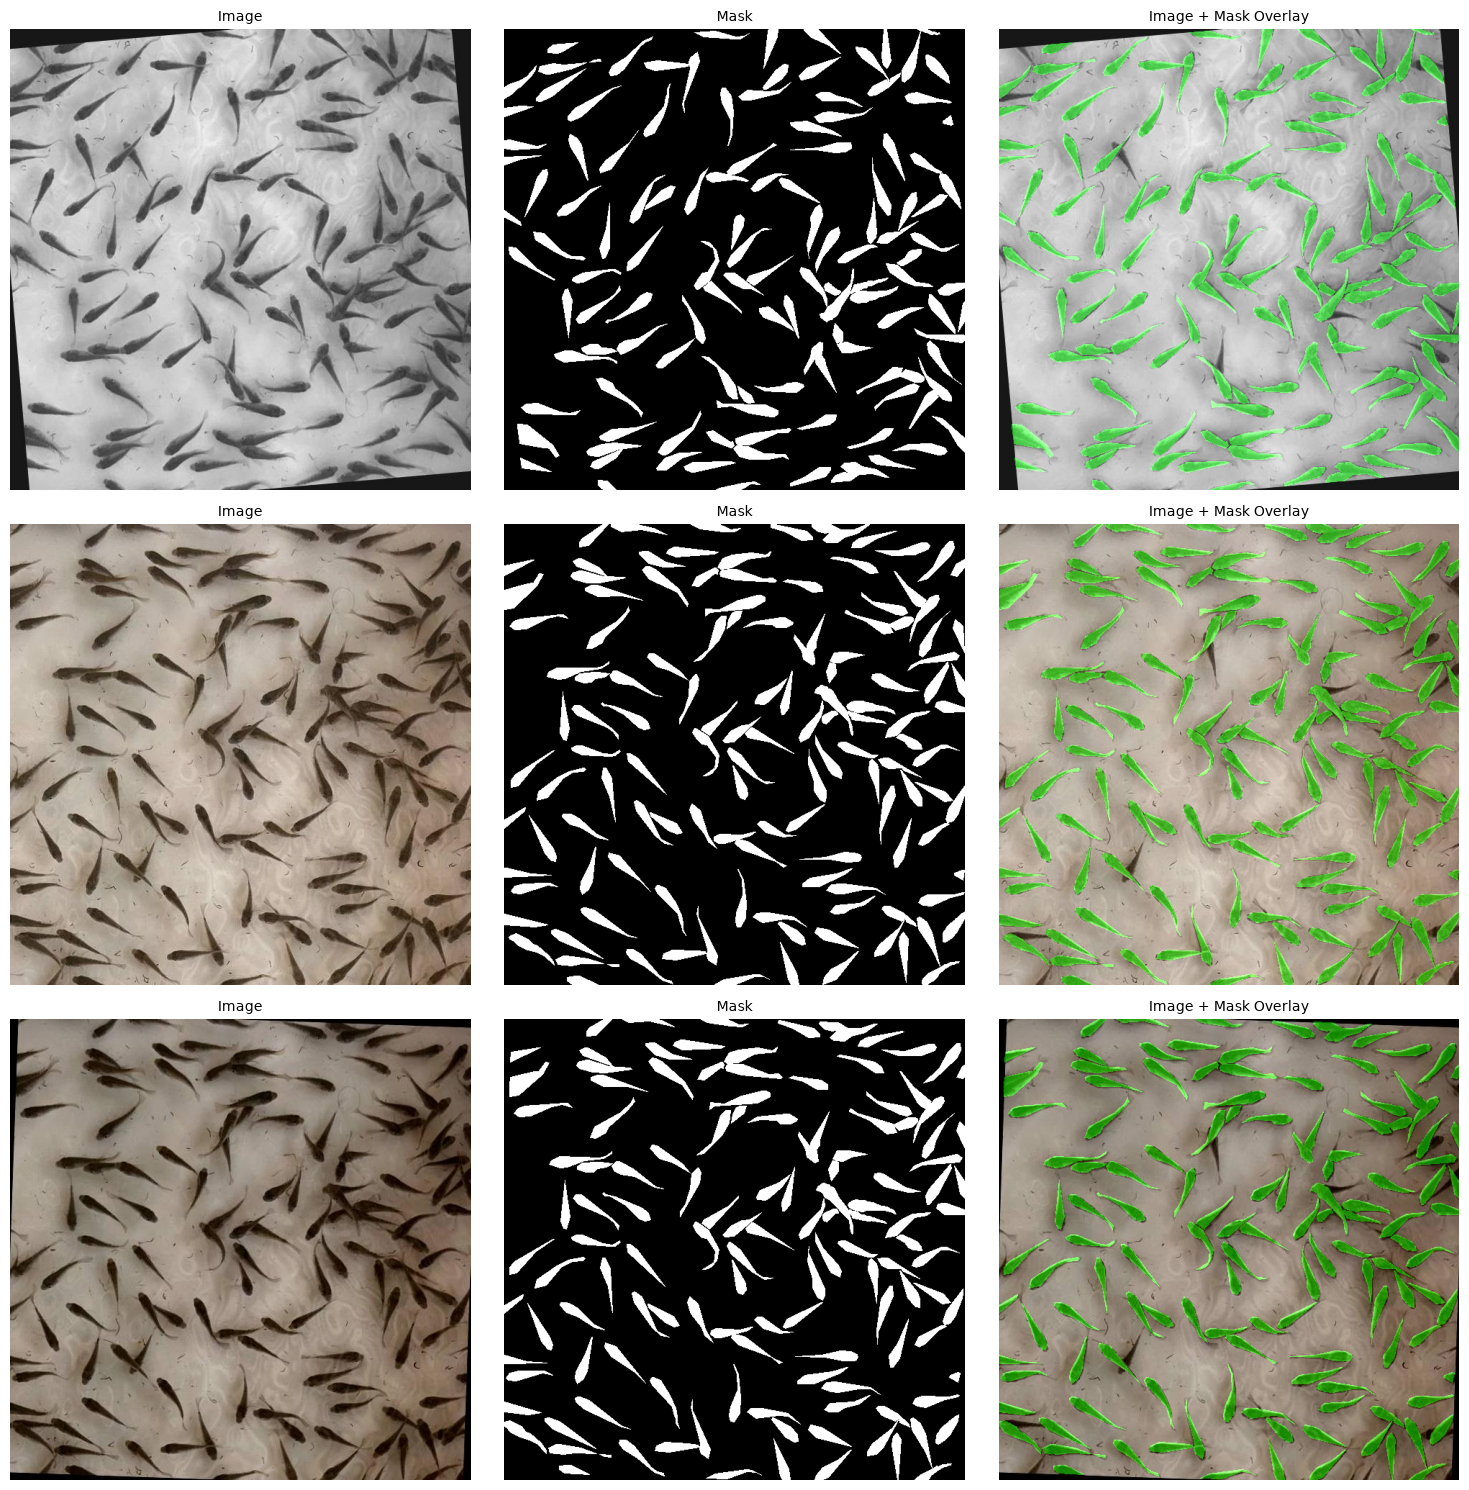

In [11]:
show_train_samples_yolo("fish_dataset_5_images2")

#### Train Model

In [12]:
results = model.train(
    data="../data/fish_dataset_5_images2/data.yaml",   
    epochs=200,             
    imgsz=640,              
    batch=4,                
    device="cpu",          
    workers=0,            
    patience=8,             
    save=True,    
    cache=False,           
    project="../models/fish_counting_seg_v3",
    name="train_ep1",      
    exist_ok=True,
    seed=SEED
)

New https://pypi.org/project/ultralytics/8.4.204 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.194 🚀 Python-3.12.4 torch-2.15.0 CPU (Apple M3)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../data/fish_dataset_5_images2/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=../models/yolov8m-seg.pt, m

#### Evaluation

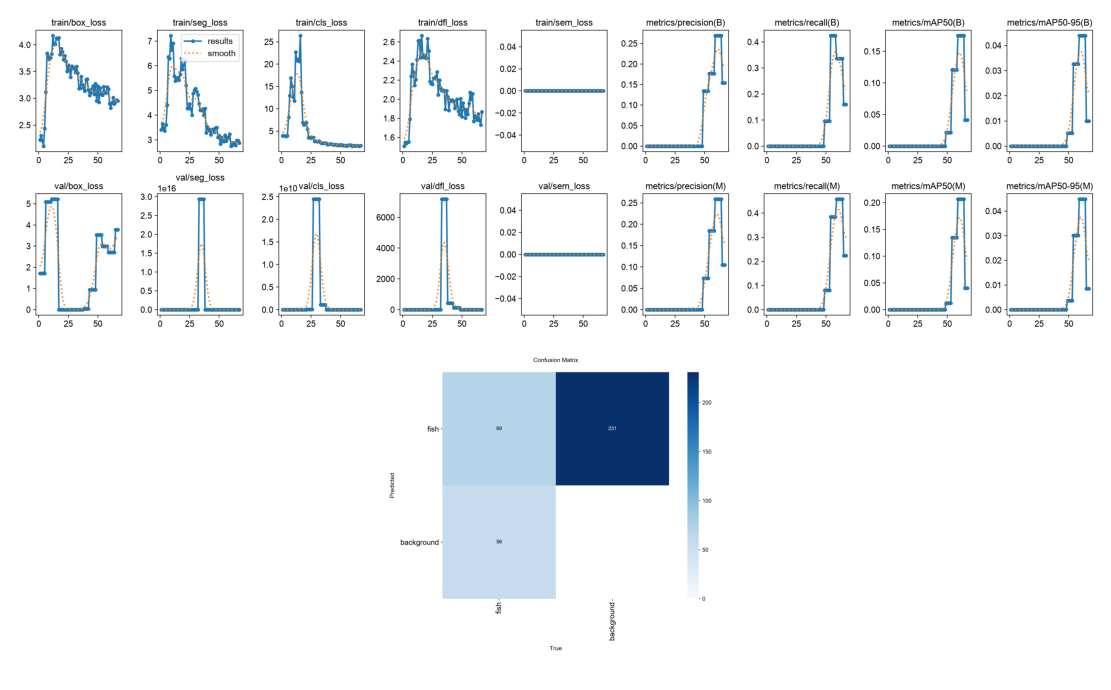

In [13]:
evaluataion("fish_counting_seg_v3")

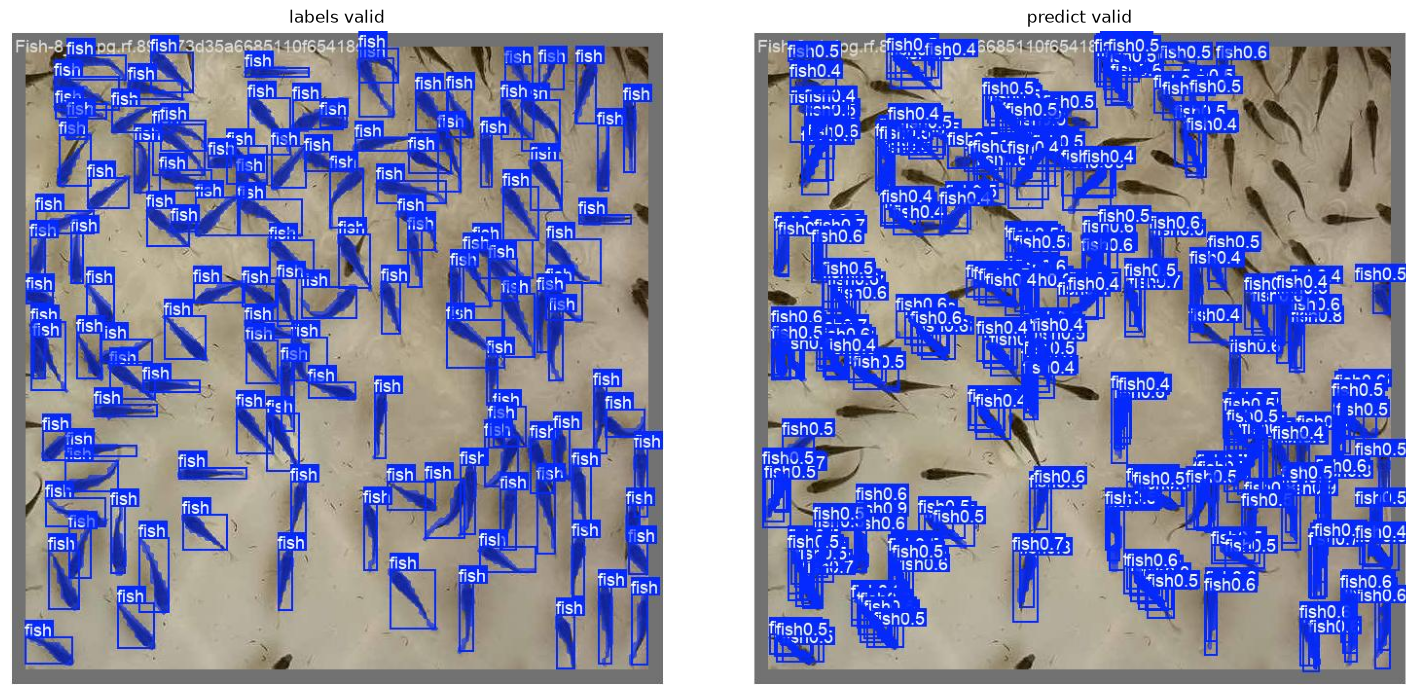

In [14]:
validation("fish_counting_seg_v3")

## Test Model

In [15]:
output_dir = "../output/yolov8m-seg"

In [16]:
detection_model = AutoDetectionModel.from_pretrained(
    model_type='yolov8',
    model_path='../runs/models/fish_counting_seg_v3/train_ep1/weights/best.pt',
    confidence_threshold=0.45,
    device='cpu'
)

### Image

In [17]:
cleaned_imgs = preprocess_test()

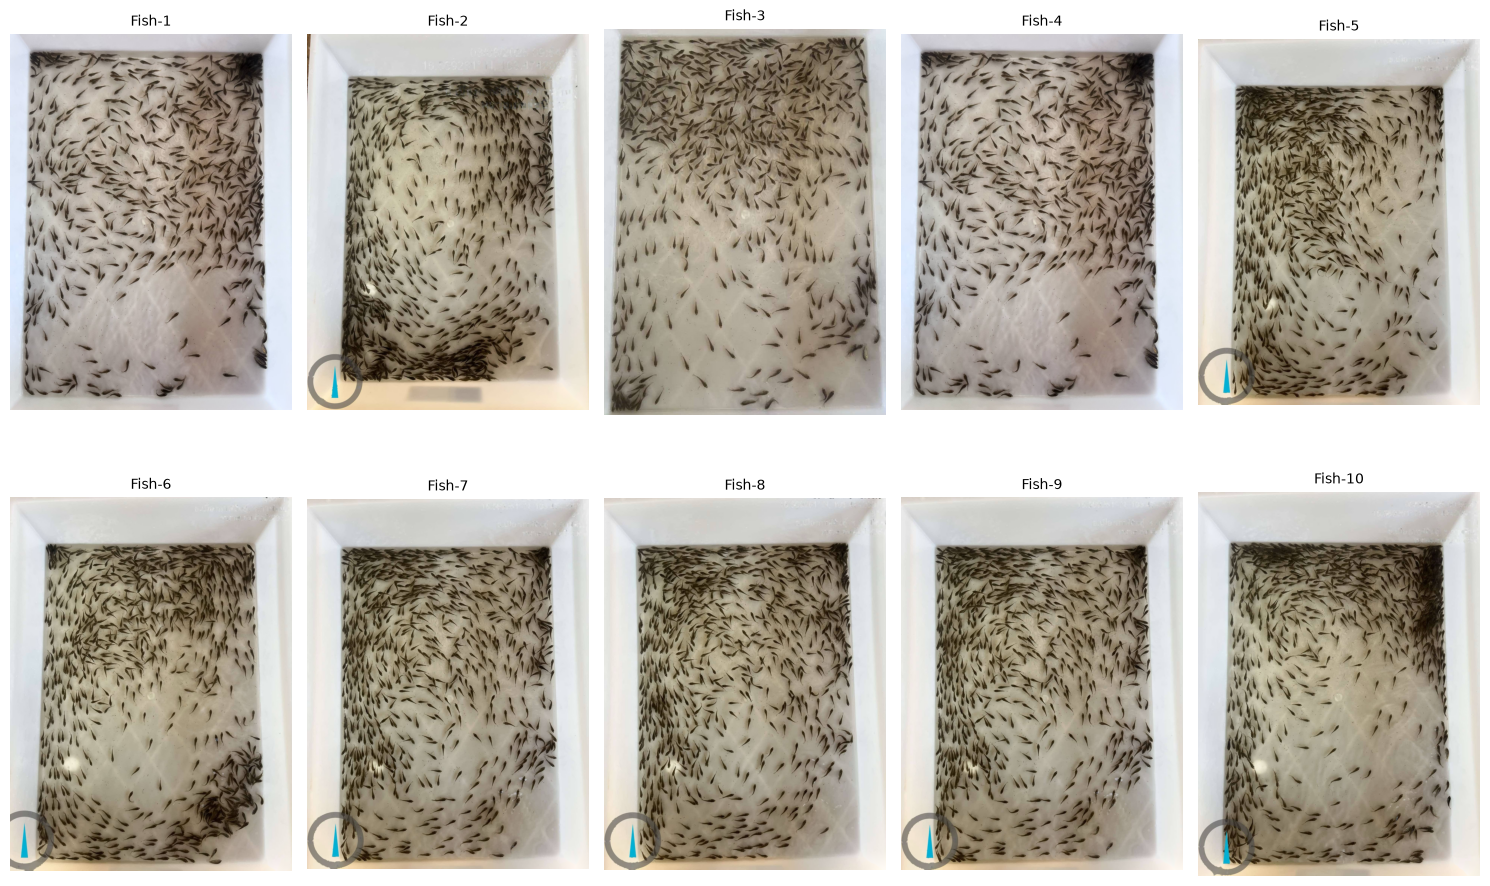

In [18]:
show_10_images(cleaned_imgs)

In [19]:
for cleaned_img in cleaned_imgs:
  result = get_sliced_prediction(
    cleaned_img["pixel_array"],
    detection_model,
    slice_height=640,
    slice_width=640,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2
  )

  total_fish = len(result.object_prediction_list)

  result.export_visuals(
    export_dir=output_dir,
    file_name=cleaned_img["name"],
    # hide_labels=True,
    rect_th=1,              
    text_size=0.5
  )

  out_image_path = f"{output_dir}/{cleaned_img["name"]}.png"
  img_out = cv2.imread(out_image_path)

  if img_out is not None:
    text = f"Total Fish: {total_fish}"
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 1.2
    thickness = 3

    (text_w, text_h), baseline = cv2.getTextSize(text, font, font_scale, thickness)
    
    x, y = 20, 20
    cv2.rectangle(img_out, (x - 10, y - 10), (x + text_w + 10, y + text_h + baseline + 10), (0, 0, 0), -1)
    
    cv2.putText(
        img_out, 
        text, 
        (x, y + text_h), 
        font, 
        font_scale, 
        (0, 255, 0), 
        thickness, 
        lineType=cv2.LINE_AA
    )

    cv2.imwrite(out_image_path, img_out)

Performing prediction on 12 slices.
Performing prediction on 12 slices.
Performing prediction on 6 slices.
Performing prediction on 12 slices.
Performing prediction on 12 slices.
Performing prediction on 12 slices.
Performing prediction on 12 slices.
Performing prediction on 12 slices.
Performing prediction on 12 slices.
Performing prediction on 12 slices.


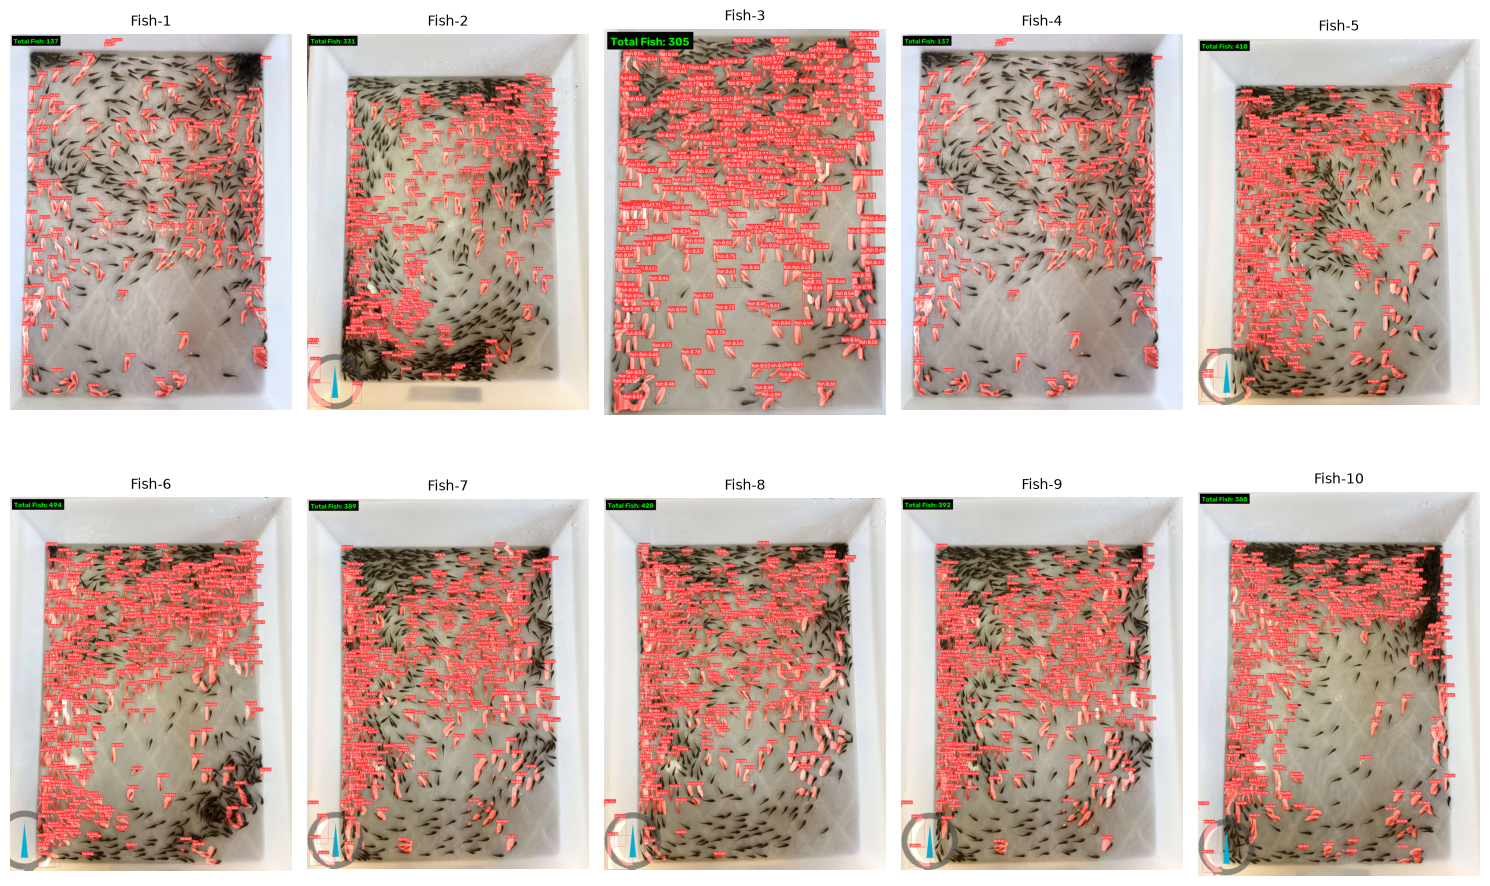

In [20]:
output_files = sorted(glob(f"{output_dir}/*.png"), key=lambda x: int(x.split("-")[-1].split(".")[0]))
output_images = []

for file in output_files:
  file_name = file.split("/")[-1].split(".")[0]
  img = cv2.imread(file)
  img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  output_images.append({"name": file_name,
                        "pixel_array": img_rgb})

show_10_images(output_images)

### Video

In [21]:
def clean_watermark(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    
    _, text_mask = cv2.threshold(gray, 235, 255, cv2.THRESH_BINARY)
    
    kernel = np.ones((3, 3), np.uint8)
    text_mask = cv2.dilate(text_mask, kernel, iterations=2)
    
    cleaned = cv2.inpaint(image, text_mask, inpaintRadius=3, flags=cv2.INPAINT_TELEA)
    return cleaned

In [22]:
video_files = sorted(glob("../data/test_fish/*.mp4"))

BOX_COLOR = (0, 255, 0)
MASK_COLOR = (0, 255, 100)
alpha = 0.35

In [23]:
for v_idx, video_input_path in enumerate(video_files, 1):
  v_path = video_input_path
  video_output_path = f"{output_dir}/vdo-{v_idx}.mp4"

  cap = cv2.VideoCapture(str(v_path))
  if not cap.isOpened():
    print(f"[{v_idx}/{len(video_files)}] Error: Cannot open file: {v_path}")
    continue

  width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
  height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
  fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
  total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

  fourcc = cv2.VideoWriter_fourcc(*"mp4v")
  out = cv2.VideoWriter(str(video_output_path), fourcc, fps, (width, height))

  print(
      f"[{v_idx}/{len(video_files)}] Processing: {v_path} ({width}x{height} |"
      f" {total_frames} frames)"
  )

  frame_idx = 0
  while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
      break

    frame_idx += 1

    cleaned_frame = clean_watermark(frame)

    frame_rgb = cv2.cvtColor(cleaned_frame, cv2.COLOR_BGR2RGB)
    result = get_sliced_prediction(
        frame_rgb,
        detection_model,
        slice_height=640,
        slice_width=640,
        overlap_height_ratio=0.2,
        overlap_width_ratio=0.2,
        verbose=0,
    )

    fish_count = len(result.object_prediction_list)

    overlay = frame.copy()
    for obj in result.object_prediction_list:
      if obj.mask is not None:
        for poly in obj.mask.segmentation:
          pts = np.array(poly, dtype=np.int32).reshape((-1, 1, 2))
          cv2.fillPoly(overlay, [pts], MASK_COLOR)

      box = obj.bbox
      x1, y1, x2, y2 = (
          int(box.minx),
          int(box.miny),
          int(box.maxx),
          int(box.maxy),
      )
      cv2.rectangle(frame, (x1, y1), (x2, y2), BOX_COLOR, thickness=1)

    cv2.addWeighted(overlay, alpha, frame, 1 - alpha, 0, frame)

    banner_text = (
        f"Fish Count: {fish_count} | Frame: {frame_idx}/{total_frames}"
    )
    (text_w, text_h), baseline = cv2.getTextSize(
        banner_text, cv2.FONT_HERSHEY_SIMPLEX, 1.0, 2
    )
    cv2.rectangle(
        frame,
        (20, 20),
        (20 + text_w + 20, 20 + text_h + baseline + 20),
        (0, 0, 0),
        -1,
    )
    cv2.putText(
        frame,
        banner_text,
        (30, 20 + text_h + 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.0,
        (0, 255, 0),
        2,
        cv2.LINE_AA,
    )

    out.write(frame)

    if frame_idx % 15 == 0 or frame_idx == total_frames:
      print(
          f"  > Frame: {frame_idx}/{total_frames} | Detected: {fish_count}"
          " fish",
          end="\r",
      )

  cap.release()
  out.release()
  print(f"\n  [OK] Saved to: {video_output_path}\n")

print("All videos processed successfully.")

[1/2] Processing: ../data/test_fish/vdo-1.mp4 (576x1024 | 219 frames)
  > Frame: 219/219 | Detected: 219 fish
  [OK] Saved to: ../output/yolov8m-seg/vdo-1.mp4

[2/2] Processing: ../data/test_fish/vdo-2.mp4 (576x1024 | 301 frames)
  > Frame: 301/301 | Detected: 147 fish
  [OK] Saved to: ../output/yolov8m-seg/vdo-2.mp4

All videos processed successfully.


## Sumary

โมเดลที่ได้มาสามารถนับปลาได้ แค่ติดปัญหาตรงที่ยังไม่สามราถทำงานได้ดีพอ คือ
- ปลาที่อยู่ทับกันเป็นกระจุกใหญ่
- นับพลาดตัวปลาเยอะ ค่าความมั่นใจตัวปลาที่ทำนายต่ำ